In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

Mounted at /content/drive


In [2]:
base_path = "/content/drive/MyDrive/churn_project/data/splits"

train = pd.read_csv(f"{base_path}/train.csv")
validation = pd.read_csv(f"{base_path}/validation.csv")
test = pd.read_csv(f"{base_path}/test.csv")

print("Train shape:", train.shape)
print("Validation shape:", validation.shape)
print("Test shape:", test.shape)

display(train.head())

Train shape: (2201, 12)
Validation shape: (482, 12)
Test shape: (467, 12)


,row_id,Call Failure,Subscription Length,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Complains,Charge Amount,Tariff Plan,Status,Churn
0,1,0,39,318,5,7,4,0,0,1,2,0
1,2,10,37,2453,60,359,24,0,0,1,1,0
2,3,10,38,4198,66,1,35,0,0,1,1,0
3,4,3,38,2393,58,2,33,0,0,1,1,0
4,5,11,38,3775,82,32,28,0,1,1,1,0


In [3]:
# Separate the input features from the target column

# Remove row_id because it is only an identifier
# Remove Churn because it is the target we want to predict
X_train = train.drop(columns=["row_id", "Churn"])
X_validation = validation.drop(columns=["row_id", "Churn"])
X_test = test.drop(columns=["row_id", "Churn"])

# Store the target column separately
y_train = train["Churn"]
y_validation = validation["Churn"]
y_test = test["Churn"]

# Check the shapes after separating features and target
print("X_train shape:", X_train.shape)
print("X_validation shape:", X_validation.shape)
print("X_test shape:", X_test.shape)

# Display the feature names
print("\nFeatures:")
print(X_train.columns.tolist())

# Display the class counts in each split
print("\nTrain Churn counts:")
print(y_train.value_counts())

print("\nValidation Churn counts:")
print(y_validation.value_counts())

print("\nTest Churn counts:")
print(y_test.value_counts())

X_train shape: (2201, 10)
X_validation shape: (482, 10)
X_test shape: (467, 10)

Features:
['Call Failure', 'Subscription Length', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Complains', 'Charge Amount', 'Tariff Plan', 'Status']

Train Churn counts:
Churn
0    1855
1     346
Name: count, dtype: int64

Validation Churn counts:
Churn
0    402
1     80
Name: count, dtype: int64

Test Churn counts:
Churn
0    398
1     69
Name: count, dtype: int64


In [4]:
# Define the numeric features
numeric_features = [
    "Call Failure",
    "Subscription Length",
    "Seconds of Use",
    "Frequency of use",
    "Frequency of SMS",
    "Distinct Called Numbers"
]

# Define the categorical features
categorical_features = [
    "Charge Amount",
    "Tariff Plan",
    "Status"
]

# Complains is already a binary feature, so we keep it as it is
binary_features = ["Complains"]

# Preprocessing for Logistic Regression:
# 1. Standardize numeric features
# 2. One-hot encode categorical features
# 3. Keep the binary feature unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("binary", "passthrough", binary_features)
    ]
)

print("Preprocessor is ready.")

Preprocessor is ready.


In [5]:
# Create a list to store the validation results
results = []

# Try the planned values of C and class_weight
for C_value in [0.1, 1, 10]:
    for weight in [None, "balanced"]:

        # Build the Logistic Regression pipeline
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(
                C=C_value,
                class_weight=weight,
                penalty="l2",
                solver="liblinear",
                random_state=433,
                max_iter=1000
            ))
        ])

        # Train the model using the training data
        model.fit(X_train, y_train)

        # Predict probabilities on the validation set
        validation_prob = model.predict_proba(X_validation)[:, 1]

        # Calculate Average Precision on the validation set
        ap_score = average_precision_score(y_validation, validation_prob)

        # Save the results
        results.append({
            "C": C_value,
            "class_weight": weight,
            "validation_AP": ap_score
        })

# Convert the results to a DataFrame
results_df = pd.DataFrame(results)

# Sort from best to worst validation AP
results_df = results_df.sort_values(
    by="validation_AP",
    ascending=False
).reset_index(drop=True)

# Display all configurations
display(results_df)

,C,class_weight,validation_AP
0,10.0,None,0.782559
1,1.0,None,0.778133
2,10.0,balanced,0.772421
3,1.0,balanced,0.768100
4,0.1,None,0.752362
5,0.1,balanced,0.747721


In [6]:
# Build the best Logistic Regression model
best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=10,
        class_weight=None,
        penalty="l2",
        solver="liblinear",
        random_state=433,
        max_iter=1000
    ))
])

# Train the best model using the training data
best_model.fit(X_train, y_train)

# Predict churn probabilities on the validation set
validation_prob = best_model.predict_proba(X_validation)[:, 1]

print("Best Logistic Regression model is trained.")

Best Logistic Regression model is trained.


In [8]:
# Create a list to store threshold results
threshold_results = []

# Try thresholds from 0.05 to 0.95
for threshold in np.arange(0.05, 1.00, 0.05):

    # Convert probabilities into class predictions
    validation_pred = (validation_prob >= threshold).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(y_validation, validation_pred, zero_division=0)
    recall = recall_score(y_validation, validation_pred, zero_division=0)
    f1 = f1_score(y_validation, validation_pred, zero_division=0)

    # Save the results
    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

# Convert results to a DataFrame
threshold_df = pd.DataFrame(threshold_results)

# Sort by F1-score from highest to lowest
threshold_df = threshold_df.sort_values(
    by=["f1_score", "threshold"],
    ascending=[False, False]
).reset_index(drop=True)

# Display the threshold results
display(threshold_df)

,threshold,precision,recall,f1_score
0,0.35,0.636364,0.7875,0.703911
1,0.25,0.589744,0.8625,0.700508
2,0.30,0.600000,0.8250,0.694737
3,0.40,0.683544,0.6750,0.679245
4,0.20,0.538462,0.8750,0.666667
5,0.15,0.493151,0.9000,0.637168
6,0.45,0.716667,0.5375,0.614286
7,0.10,0.423077,0.9625,0.587786
8,0.50,0.787234,0.4625,0.582677
9,0.55,0.818182,0.4500,0.580645


In [9]:
# Save the selected threshold
best_threshold = 0.35

# Predict churn probabilities on the test set
test_prob = best_model.predict_proba(X_test)[:, 1]

# Make final predictions using the selected threshold
test_pred = (test_prob >= best_threshold).astype(int)

# Calculate the final test metrics
test_accuracy = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred, zero_division=0)
test_recall = recall_score(y_test, test_pred, zero_division=0)
test_f1 = f1_score(y_test, test_pred, zero_division=0)
test_ap = average_precision_score(y_test, test_prob)
test_roc_auc = roc_auc_score(y_test, test_prob)

# Display the final results
print("Final Logistic Regression Test Results")
print("--------------------------------------")
print("Threshold:", best_threshold)
print("Accuracy:", round(test_accuracy, 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("F1-score:", round(test_f1, 4))
print("Average Precision (AP):", round(test_ap, 4))
print("ROC-AUC:", round(test_roc_auc, 4))

Final Logistic Regression Test Results
--------------------------------------
Threshold: 0.35
Accuracy: 0.8822
Precision: 0.6
Recall: 0.6087
F1-score: 0.6043
Average Precision (AP): 0.7171
ROC-AUC: 0.9284


In [10]:
# Calculate the confusion matrix
cm = confusion_matrix(y_test, test_pred)

# Display the confusion matrix
print("Confusion Matrix:")
print(cm)

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, test_pred, digits=4))

Confusion Matrix:
[[370  28]
 [ 27  42]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9320    0.9296    0.9308       398
           1     0.6000    0.6087    0.6043        69

    accuracy                         0.8822       467
   macro avg     0.7660    0.7692    0.7676       467
weighted avg     0.8829    0.8822    0.8826       467



In [12]:
# Path to the results folder
results_path = "/content/drive/MyDrive/churn_project/results"

# Create the results folder if it does not already exist
import os
os.makedirs(results_path, exist_ok=True)

# Save the hyperparameter tuning results
results_df.to_csv(
    f"{results_path}/logistic_regression_tuning.csv",
    index=False
)

# Save the threshold tuning results
threshold_df.to_csv(
    f"{results_path}/logistic_regression_thresholds.csv",
    index=False
)

# Create a table with the final test metrics
final_metrics = pd.DataFrame([{
    "model": "Logistic Regression",
    "C": 10,
    "class_weight": "None",
    "threshold": 0.35,
    "accuracy": test_accuracy,
    "precision": test_precision,
    "recall": test_recall,
    "f1_score": test_f1,
    "average_precision": test_ap,
    "roc_auc": test_roc_auc
}])

# Save the final test metrics
final_metrics.to_csv(
    f"{results_path}/logistic_regression_metrics.csv",
    index=False
)

# Save the test predictions and probabilities
predictions = pd.DataFrame({
    "row_id": test["row_id"],
    "actual_churn": y_test.values,
    "predicted_churn": test_pred,
    "churn_probability": test_prob
})

predictions.to_csv(
    f"{results_path}/logistic_regression_predictions.csv",
    index=False
)

# Save the confusion matrix
confusion_matrix_df = pd.DataFrame(
    cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

confusion_matrix_df.to_csv(
    f"{results_path}/logistic_regression_confusion_matrix.csv"
)

print("Logistic Regression results saved successfully.")

Logistic Regression results saved successfully.


In [13]:
# Create predictions using the default threshold of 0.50
test_pred_default = (test_prob >= 0.50).astype(int)

# Calculate metrics for threshold 0.50
default_accuracy = accuracy_score(y_test, test_pred_default)
default_precision = precision_score(y_test, test_pred_default, zero_division=0)
default_recall = recall_score(y_test, test_pred_default, zero_division=0)
default_f1 = f1_score(y_test, test_pred_default, zero_division=0)

# Create a comparison table
threshold_comparison = pd.DataFrame([
    {
        "threshold": 0.35,
        "accuracy": test_accuracy,
        "precision": test_precision,
        "recall": test_recall,
        "f1_score": test_f1
    },
    {
        "threshold": 0.50,
        "accuracy": default_accuracy,
        "precision": default_precision,
        "recall": default_recall,
        "f1_score": default_f1
    }
])

# Display the comparison
display(threshold_comparison)

# Save the comparison table
threshold_comparison.to_csv(
    f"{results_path}/logistic_regression_threshold_comparison.csv",
    index=False
)

,threshold,accuracy,precision,recall,f1_score
0,0.35,0.882227,0.600000,0.608696,0.604317
1,0.50,0.880086,0.685714,0.347826,0.461538


In [14]:
# Get the fitted preprocessor and classifier from the pipeline
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["classifier"]

# Get the final feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get the Logistic Regression coefficients
coefficients = fitted_classifier.coef_[0]

# Create a table with feature names and coefficients
coefficients_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Add the absolute coefficient value for sorting
coefficients_df["absolute_coefficient"] = coefficients_df["coefficient"].abs()

# Sort features by the strongest coefficients
coefficients_df = coefficients_df.sort_values(
    by="absolute_coefficient",
    ascending=False
).reset_index(drop=True)

# Display the coefficient table
display(coefficients_df)

# Save the coefficients
coefficients_df.to_csv(
    f"{results_path}/logistic_regression_coefficients.csv",
    index=False
)

,feature,coefficient,absolute_coefficient
0,binary__Complains,3.730359,3.730359
1,categorical__Charge Amount_8,-3.354544,3.354544
2,categorical__Charge Amount_9,-3.053818,3.053818
3,categorical__Charge Amount_10,-2.986654,2.986654
4,categorical__Charge Amount_0,2.957919,2.957919
5,numeric__Frequency of use,-2.950630,2.950630
6,categorical__Charge Amount_1,2.927821,2.927821
7,categorical__Charge Amount_2,2.777819,2.777819
8,categorical__Status_1,-2.102757,2.102757
9,categorical__Tariff Plan_1,-1.893381,1.893381


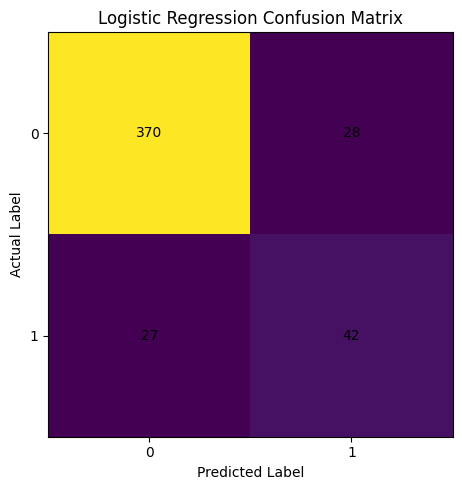

In [16]:
# Plot the confusion matrix
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["0", "1"])
plt.yticks([0, 1], ["0", "1"])

# Add the values inside the matrix
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.tight_layout()

# Save the figure
plt.savefig(
    f"{results_path}/logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Show all Logistic Regression result files saved in the results folder
saved_files = [
    file for file in os.listdir(results_path)
    if file.startswith("logistic_regression")
]

print("Saved Logistic Regression files:")
for file in sorted(saved_files):
    print("-", file)

Saved Logistic Regression files:
- logistic_regression_coefficients.csv
- logistic_regression_confusion_matrix.csv
- logistic_regression_confusion_matrix.png
- logistic_regression_metrics.csv
- logistic_regression_predictions.csv
- logistic_regression_threshold_comparison.csv
- logistic_regression_thresholds.csv
- logistic_regression_tuning.csv
